# Confirmation de CAMeLBERT sur trois graines

Les taux sont maintenant fixés : **5e-5 pour TSAC**, **2e-5 pour MADAR**, d’après le criblage Mac conservé. Nous entraînons chaque tâche sur **13, 42 et 2026**, puis rapportons les trois scores, leur moyenne et leur écart-type. Aucun taux n’est recherché dans ce notebook.

Le mode **full**, par défaut, lance **six nouveaux entraînements complets**, après les contrôles automatiques. Pour consulter une campagne existante sans entraîner, choisir **replay** avec le dossier et le mode attendus. Ne pas lancer une seconde campagne pendant qu’une exécution est déjà en cours.

Prérequis : dépôt, profil encodeur installé, sources autorisées et poids généraux épinglés présents. Le test officiel reste exclu. Voir `docs/55_protocole_confirmation_encodeur.md`.


## 1. Choisir le mode

`full` entraîne sur tout le train et mesure toute la validation, pour trois graines par tâche. `smoke` réalise seulement les quatre modèles techniques sur100exemples. `replay` contrôle et affiche une campagne existante sans apprentissage. `off` ne charge aucun corpus ou modèle.


In [1]:
from pathlib import Path
import json
import os
import sys

explicit_root = os.environ.get('TUNISCOPE_PROJECT_ROOT')
candidates = ([Path(explicit_root)] if explicit_root else []) + [
    Path.cwd(), *Path.cwd().parents, Path('/kaggle/working/tuniscope'),
]
ROOT = next((p.resolve() for p in candidates
             if (p / 'scripts/run_encoder_confirmation.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Ouvrir depuis le dépôt à jour ou définir TUNISCOPE_PROJECT_ROOT.')
sys.path.insert(0, str(ROOT / 'scripts'))
from encoder_confirmation_notebook_support import notebook_run, campaign_figures

TRAINING_MODE = os.environ.get('TUNISCOPE_CONFIRMATION_MODE', 'full')
DEVICE = os.environ.get('TUNISCOPE_CONFIRMATION_DEVICE', 'auto')
REPLAY_RUN = os.environ.get('TUNISCOPE_CONFIRMATION_RUN',
    'outputs/encoder_finetuning/confirmation/2026-11-06_selected_rates_mps_full')
REPLAY_EXPECTED_MODE = os.environ.get('TUNISCOPE_CONFIRMATION_REPLAY_MODE', 'full')
if TRAINING_MODE not in {'full', 'smoke', 'replay', 'off'}:
    raise ValueError('Choisir full, smoke, replay ou off')
plan = json.loads((ROOT / 'configs/camelbert_confirmation_v1.json').read_text())
print('Mode :', TRAINING_MODE, '| Appareil demandé :', DEVICE)
for corpus, rate in plan['selected_learning_rates'].items():
    print(f'{corpus.upper()} : taux fixé {rate:g}')
print('Graines de confirmation :', plan['seeds'])


Mode : full | Appareil demandé : auto
TSAC : taux fixé 5e-05
MADAR : taux fixé 2e-05
Graines de confirmation : [13, 42, 2026]


## 2. Entraîner ou contrôler la campagne existante

Chaque tâche passe un petit contrôle apparié avant ses trois adaptations complètes. Le modèle de base est rechargé au début de chaque graine. Les métriques par classe et prédictions sont conservées à chaque époque ; le meilleur checkpoint est choisi sur le macro-F1 de validation. Chaque checkpoint est ensuite rechargé et vérifié.

Les trois graines sont toutes rapportées, même si la moyenne est inférieure au score du criblage. Le rejeu de campagne contrôle fichiers, métriques et preuves archivées ; il ne relance pas l’inférence des modèles.


In [2]:
run_result = notebook_run(TRAINING_MODE, DEVICE, REPLAY_RUN, REPLAY_EXPECTED_MODE)
if run_result is not None:
    campaign_directory, campaign = run_result
    from IPython.display import display, Markdown
    display(Markdown((campaign_directory / 'summary.md').read_text()))
else:
    print('Mode off : aucun modèle, corpus ou entraînement chargé.')



=== Confirmation TSAC — taux fixé 5e-05 ===

TSAC frozen graine42 — train100, validation100 — mps
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /Users/elghoth/Desktop/NLP Project/.tools/encoders/camelbert_mix_9be352797bdf28a9ae21e2ae582aaaca7abdb22d and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
  époque1 | perte train0.7492 | val0.7371 | macro-F10.324324 | train1.0s | val0.5s
  époque2 | perte train0.7112 | val0.7125 | macro-F10.380952 | train0.5s | val0.5s

TSAC finetuned graine42 — train100, validation100 — mps
Some weights of BertForSequenceClassification were not initialized from

# Confirmation CAMeLBERT

Mode **full**. Taux fixés avant ces résultats. Test officiel non évalué.

| Corpus | Taux | Graine | Macro-F1 | Accuracy | Époque retenue |
| --- | ---: | ---: | ---: | ---: | ---: |
| TSAC | 5e-05 | 13 | 0.933368 | 0.933484 | 3 |
| TSAC | 5e-05 | 42 | 0.930285 | 0.930665 | 3 |
| TSAC | 5e-05 | 2026 | 0.928850 | 0.928974 | 3 |
| MADAR | 2e-05 | 13 | 0.954004 | 0.956250 | 3 |
| MADAR | 2e-05 | 42 | 0.954370 | 0.957500 | 3 |
| MADAR | 2e-05 | 2026 | 0.952071 | 0.953750 | 3 |

| Corpus | Macro-F1 moyen | Écart-type échantillonnal |
| --- | ---: | ---: |
| TSAC | 0.930834 | 0.002308 |
| MADAR | 0.953482 | 0.001235 |

Les trois graines sont toutes rapportées. Aucune meilleure graine sélectionnée. Validation utilisée pour sélectionner le taux ; aucun gain sur le test ni significativité établi.

Dossier : `/Users/elghoth/Desktop/NLP Project/outputs/encoder_finetuning/confirmation/notebooks/177d9f5ad78b4ef4907e97d97abe96f8_full`


## 3. Lire les figures

Chaque PNG montre pertes train/validation, macro-F1 par époque et matrice de confusion du checkpoint retenu. Les figures portent le périmètre, le taux et la graine. Une campagne full fournit six PNG ; un smoke en fournit quatre et ne constitue pas une confirmation sur trois graines.


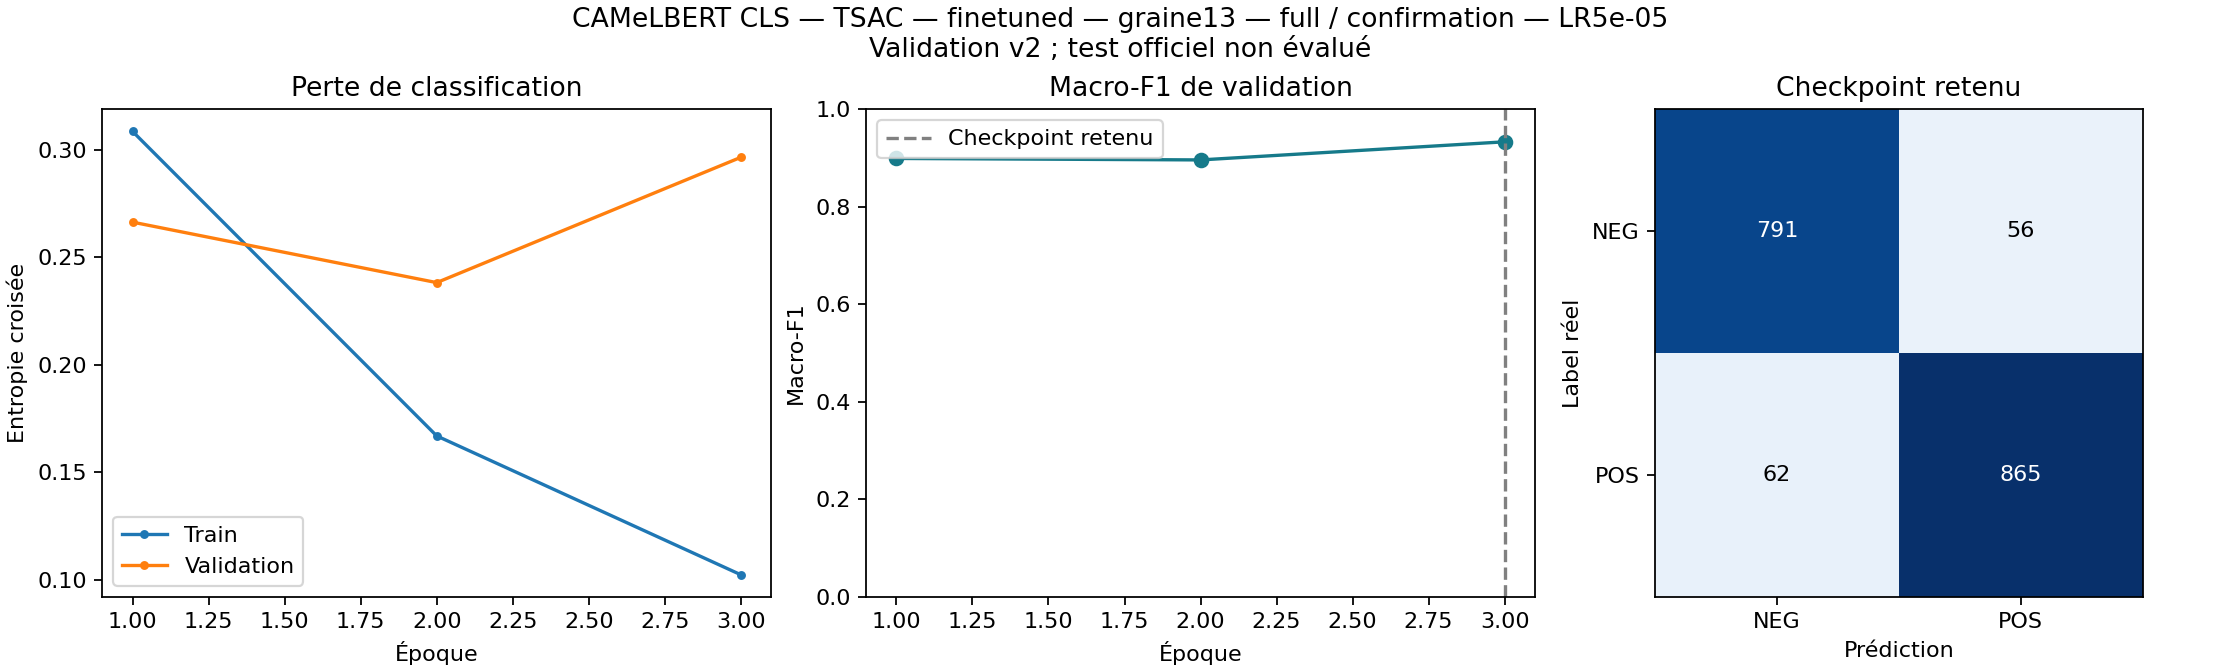

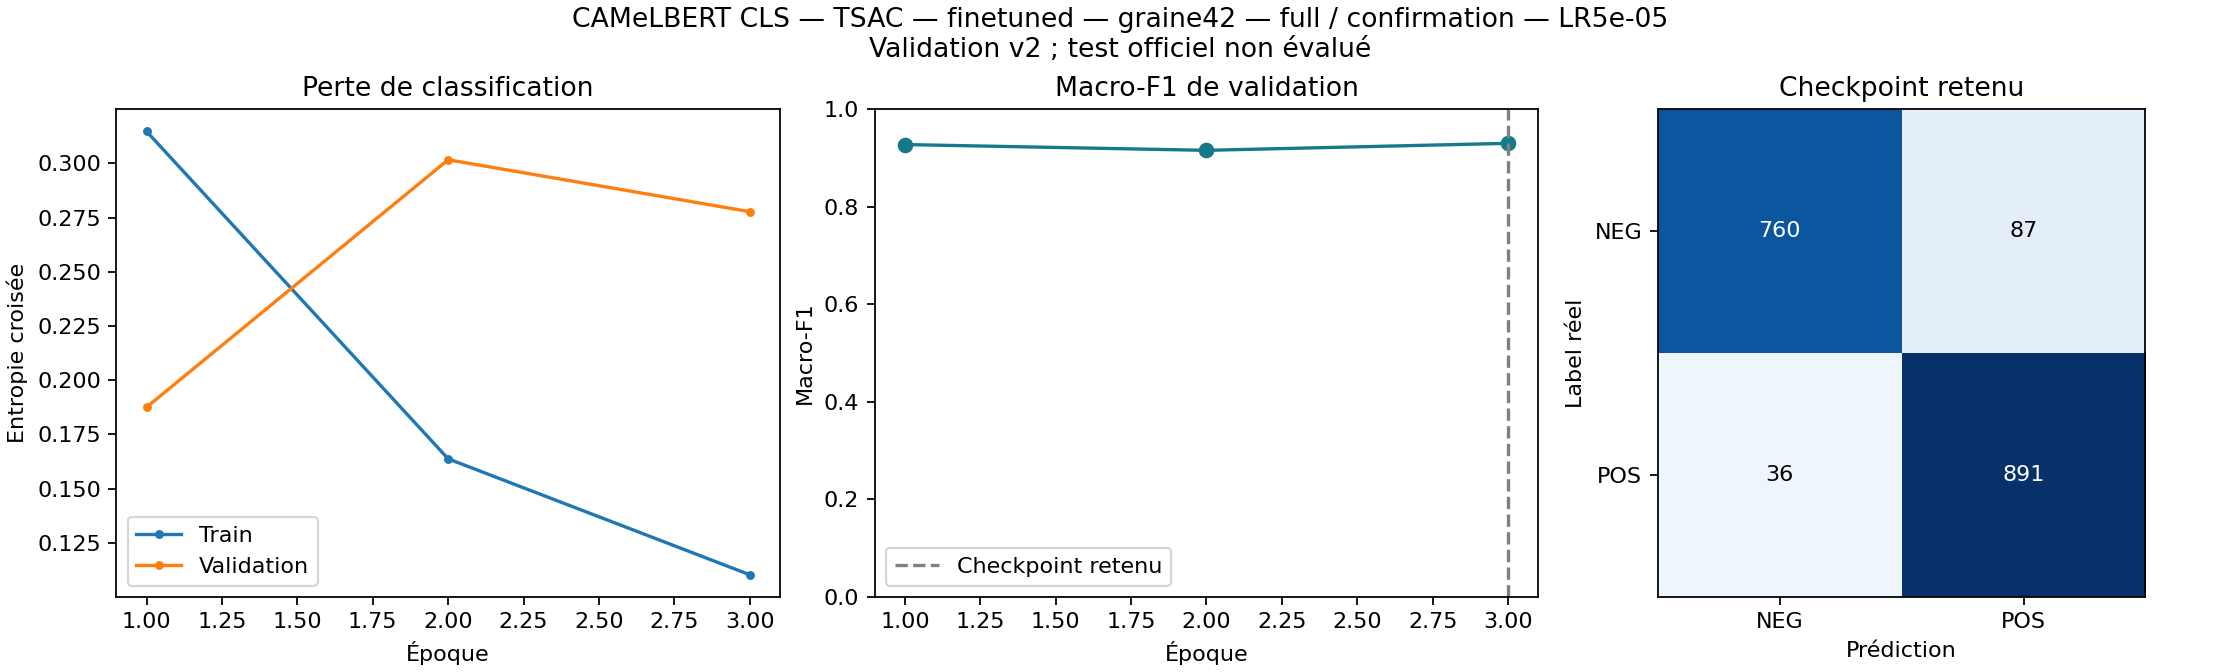

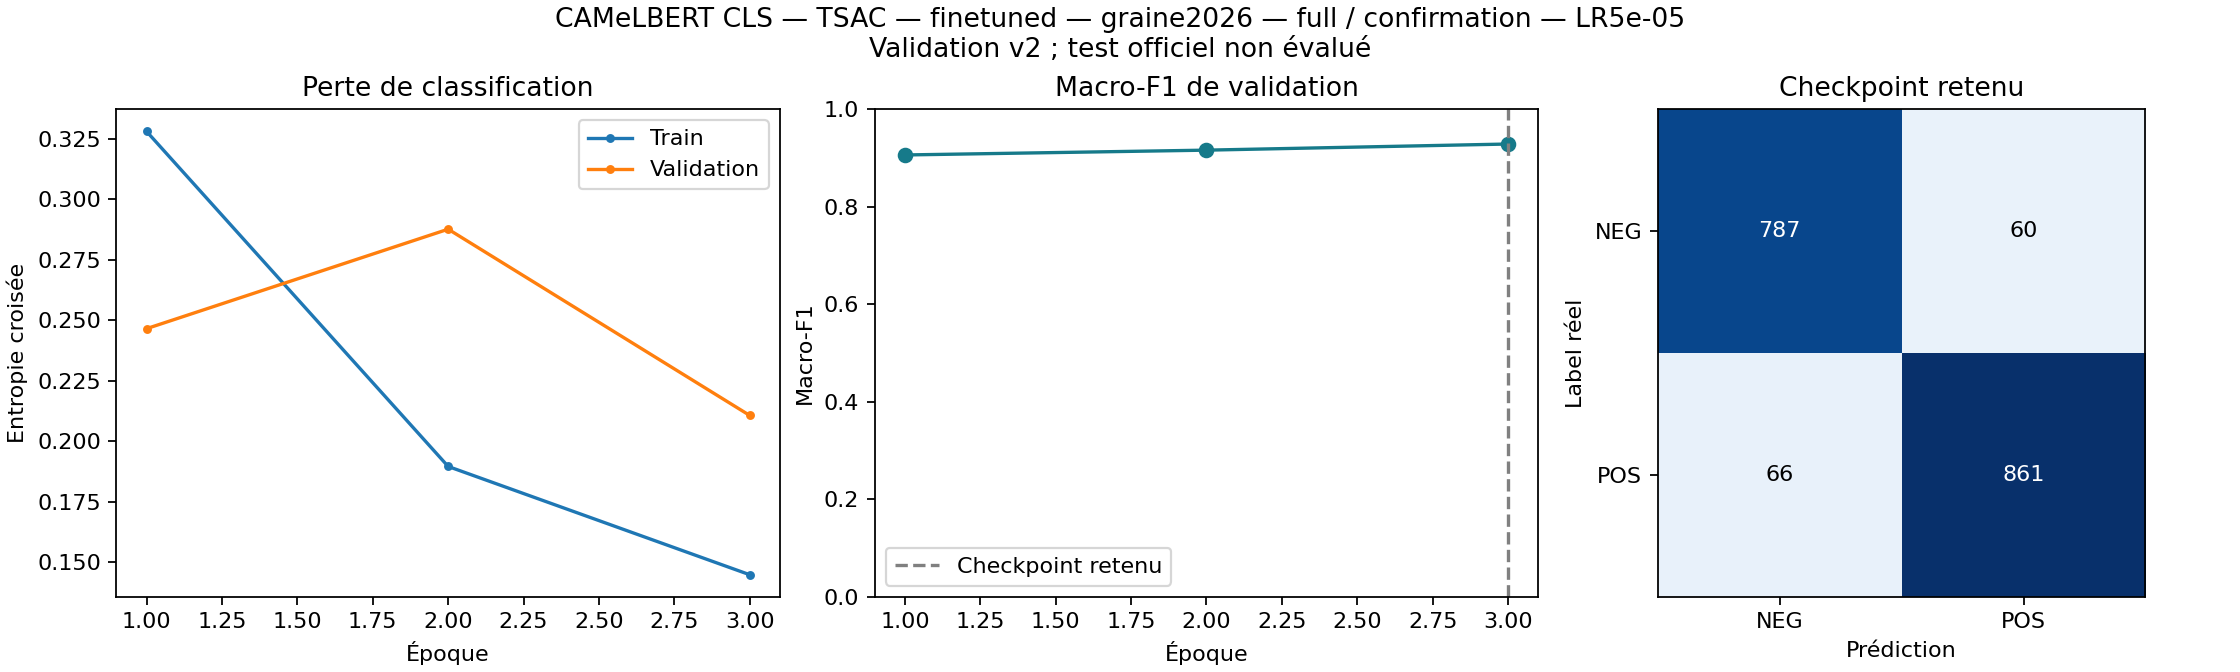

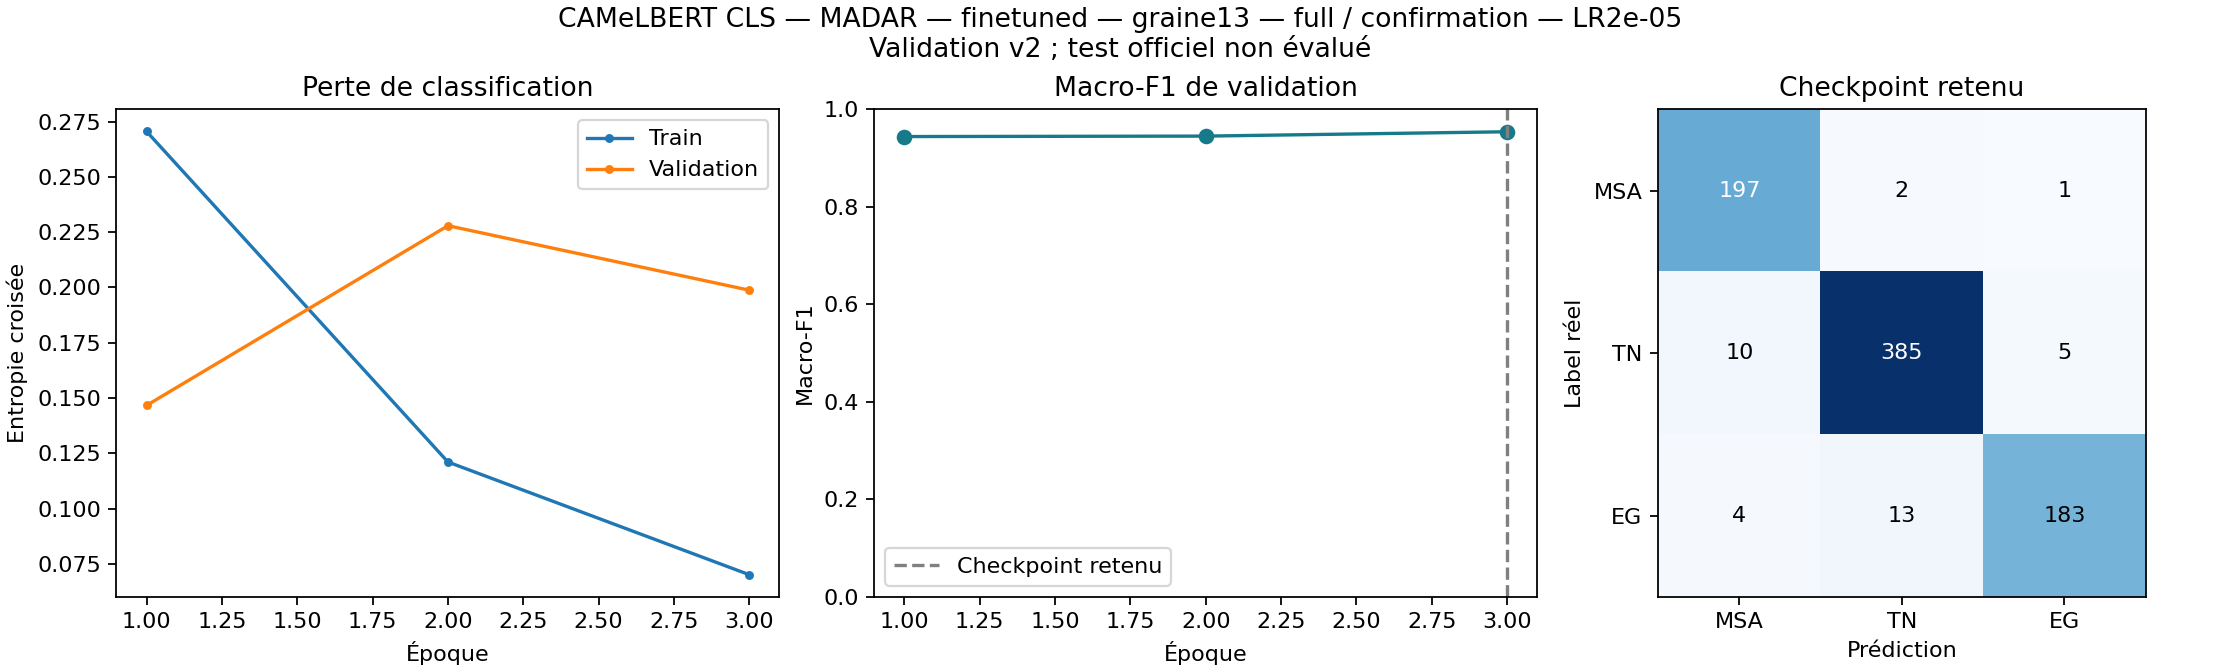

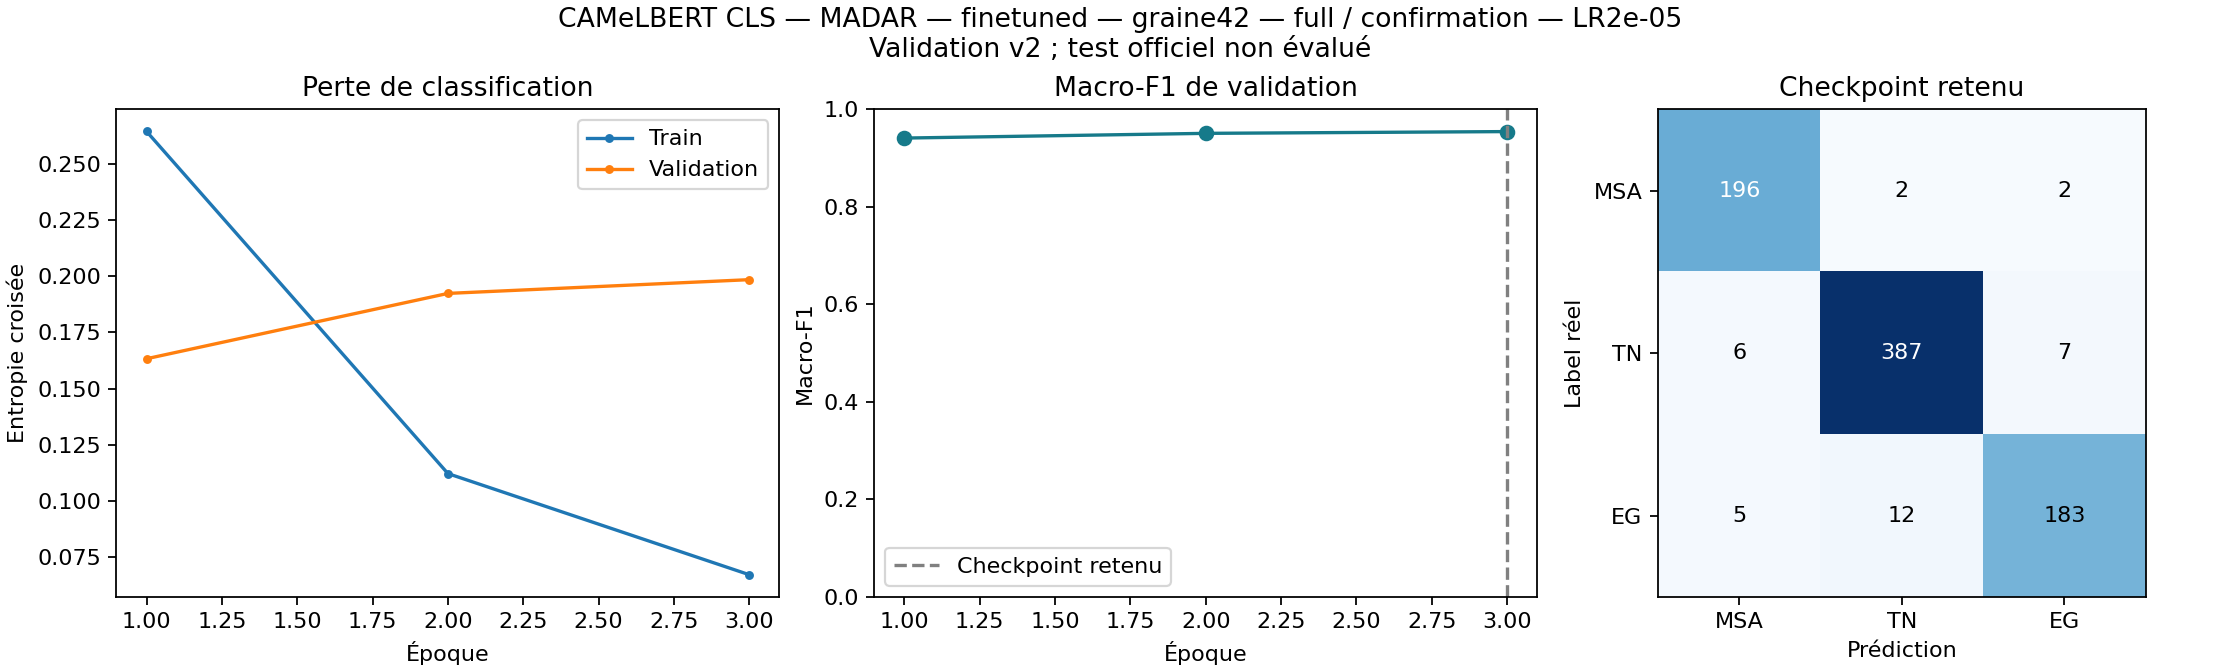

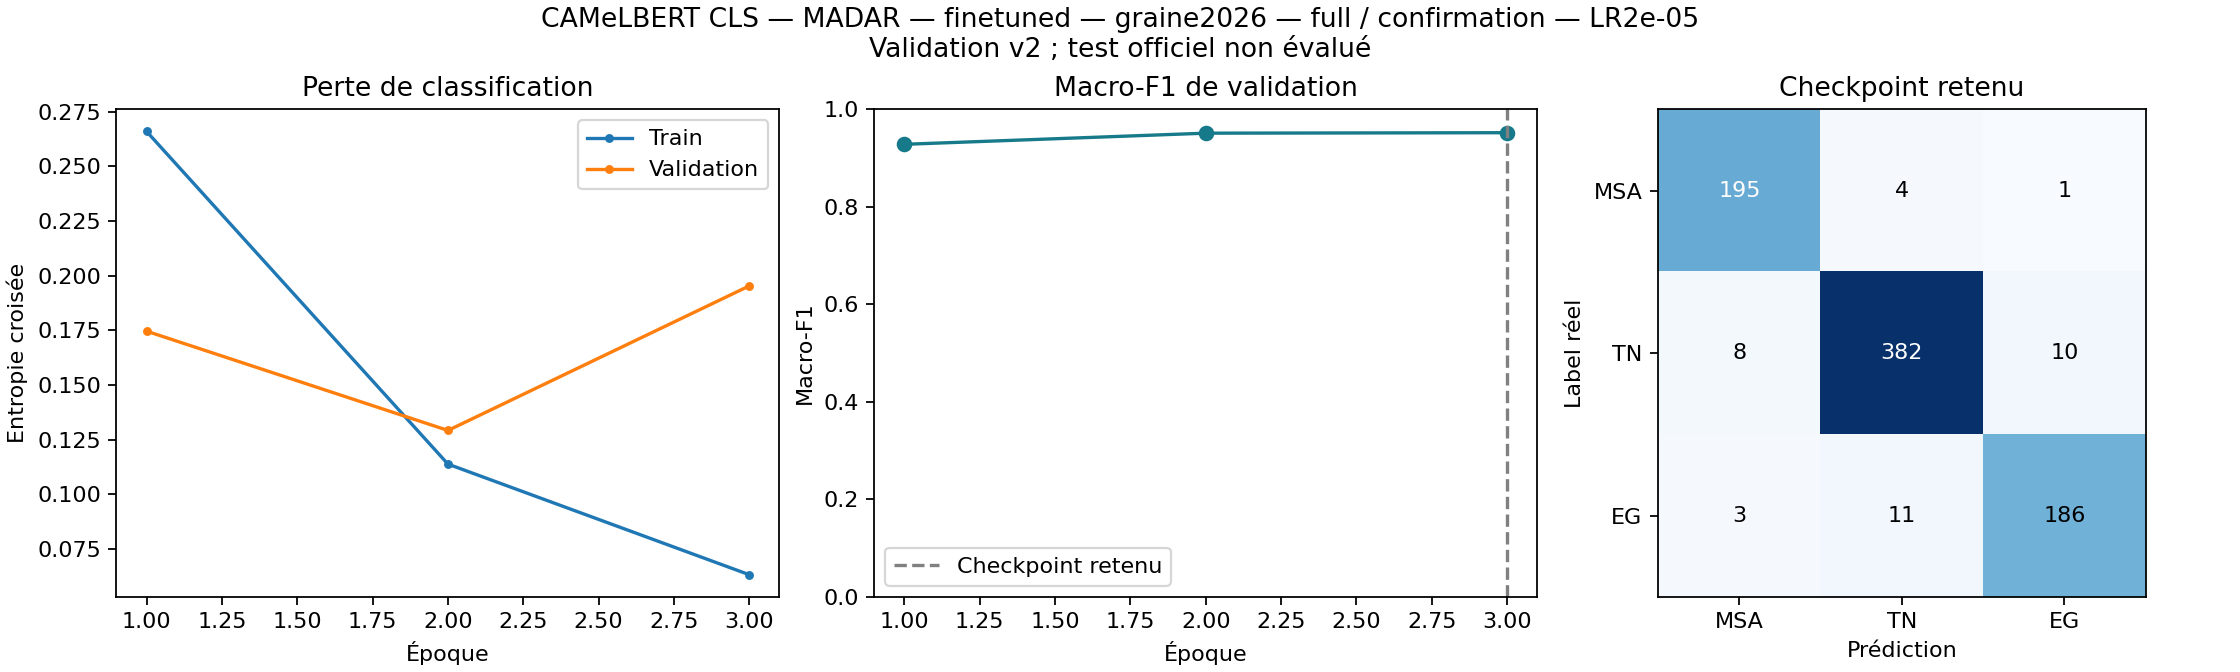

6 figures conservées dans les sous-dossiers figures/.


In [3]:
figure_paths = []
if run_result is not None:
    from IPython.display import display, Image
    figure_paths = campaign_figures(campaign_directory, campaign)
    for figure in figure_paths:
        display(Image(filename=str(figure)))
    print(f'{len(figure_paths)} figures conservées dans les sous-dossiers figures/.')


## 4. Conserver les résultats

Les checkpoints, tokenizer, mappings, journaux par époque et prédictions restent dans les dossiers des modèles. Une petite archive **evidence_without_weights.zip** regroupe les preuves et figures ; elle **ne contient pas les poids**. Pour pouvoir refaire l’inférence, conserver aussi les sous-dossiers de checkpoints. Une copie sur le même disque ou dans la même session ne remplace pas une sauvegarde indépendante.

Ces résultats restent des métriques de validation. Le test final, le bootstrap, l’application et le LLM/LoRA sont séparés.


In [4]:
if run_result is not None:
    print('Dossier de confirmation :', campaign_directory)
    print('Synthèse :', campaign_directory / 'summary.md')
    print('Contrôles :', campaign_directory / 'campaign_verification.json')
    print('Preuves légères, sans poids :', campaign_directory / 'evidence_without_weights.zip')
    if campaign['aggregates'] is None:
        print('Smoke seulement : aucune moyenne finale sur trois graines.')
    else:
        for corpus, values in campaign['aggregates'].items():
            score = values['macro_f1']
            print(f"{corpus.upper()} : Macro-F1 {score['mean']:.6f} ± {score['sample_std']:.6f} (3 graines)")


Dossier de confirmation : /Users/elghoth/Desktop/NLP Project/outputs/encoder_finetuning/confirmation/notebooks/177d9f5ad78b4ef4907e97d97abe96f8_full
Synthèse : /Users/elghoth/Desktop/NLP Project/outputs/encoder_finetuning/confirmation/notebooks/177d9f5ad78b4ef4907e97d97abe96f8_full/summary.md
Contrôles : /Users/elghoth/Desktop/NLP Project/outputs/encoder_finetuning/confirmation/notebooks/177d9f5ad78b4ef4907e97d97abe96f8_full/campaign_verification.json
Preuves légères, sans poids : /Users/elghoth/Desktop/NLP Project/outputs/encoder_finetuning/confirmation/notebooks/177d9f5ad78b4ef4907e97d97abe96f8_full/evidence_without_weights.zip
TSAC : Macro-F1 0.930834 ± 0.002308 (3 graines)
MADAR : Macro-F1 0.953482 ± 0.001235 (3 graines)
